# Chapter 1 notebook: a first metasurface model

**Topic ID:** `ms-02-scattering`.
Can a sheet change transmission phase while reflecting little power?
Predict the answer, then compare transparent, electric-like, balanced,
and detuned responses. This is an **analytical, lossless two-port model**.
It has no geometry, material dispersion data, mesh, diffraction, polarization
conversion, or fabricated-device validation. No full-wave solver is run here.

Assume normal incidence, equal real wave impedance on both sides, one
polarization, only the two specular ports, and time dependence $e^{-i\omega t}$.
All coefficients refer to the ideal sheet plane. Frequencies use THz.
The complete source ZIP retains `simulations/intro_sheet.py`.

In [1]:
from pathlib import Path
from dataclasses import asdict,replace
import sys,json,csv,hashlib,platform,html
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,HTML
ROOT=next((p for p in [Path.cwd(),*list(Path.cwd().parents)[:3]] if (p/'simulations/intro_sheet.py').is_file()),None)
if ROOT is None:raise FileNotFoundError('Extract the Chapter 1 source ZIP, preserving the simulations/ and notebooks/ folders.')
sys.path.insert(0,str(ROOT/'simulations'))
from intro_sheet import Sheet,PRESETS,response,allpass_channel,scattering_matrix,channel_group_delay_fs,MODEL_VERSION
# Edit these experiment parameters; preserve model assumptions when interpreting results.
FREQUENCY_THz=200.
FREQUENCIES_THz=np.linspace(120.,280.,801)
CUSTOM=Sheet(electric_frequency_THz=200.,magnetic_frequency_THz=200.,electric_strength=.25,magnetic_strength=.25)
PHASE_FLOOR=1e-12
DATA=ROOT/'data/chapter-01';DATA.mkdir(parents=True,exist_ok=True)
def table(headers,rows):
    def escaped(x):return html.escape(f'{x:.7g}' if isinstance(x,(float,np.floating)) else str(x))
    display(HTML('<table><thead><tr>'+''.join('<th>'+escaped(x)+'</th>' for x in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+escaped(x)+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>'))
plt.rcParams.update({'figure.dpi':125,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
print('Python',platform.python_version(),'NumPy',np.__version__,'Matplotlib',matplotlib.__version__,'Model',MODEL_VERSION)
print('Reference frequency:',FREQUENCY_THz,'THz; free-space wavelength:',299.792458/FREQUENCY_THz,'um')
table(['Parameter','Value'],asdict(CUSTOM).items())
custom_value=response(FREQUENCY_THz,CUSTOM,PHASE_FLOOR)
print('Custom response at the selected frequency: R=',float(custom_value['R']),'T=',float(custom_value['T']),'phase=',float(custom_value['phase_deg']))

Python 3.12.1 NumPy 2.4.6 Matplotlib 3.11.1 Model intro-sheet-1.0
Reference frequency: 200.0 THz; free-space wavelength: 1.4989622900000001 um


Parameter,Value
electric_frequency_THz,200
magnetic_frequency_THz,200
electric_strength,0.25
magnetic_strength,0.25


Custom response at the selected frequency: R= 0.0 T= 1.0 phase= 180.0


## 1. Define the channels

For each channel, define $u=f/f_0$, $d=1-u^2$, and

$$
C(f)=\frac{d+i a u}{d-i a u}.
$$

For real positive frequency and nonnegative strength $a$, $|C|=1$.
Set $C=1$ explicitly when $a=0$, including at $f=f_0$.
With electric-like and magnetic-like channels $C_e,C_m$, use

$$
r=\frac{C_e-C_m}{2},\qquad t=\frac{C_e+C_m}{2}.
$$

These channel contributions are not retrieved electric/magnetic dipole moments.
For the scattering matrix, the even/odd eigenvalues are $C_e$ and $-C_m$;
the minus sign gives the correct transparent limit $r=0,t=1$.
Equal exterior impedances make $R=|r|^2$ and $T=|t|^2$ here.

In [2]:
reference_rows=[];snapshots={}
for name,sheet in PRESETS.items():
    v=response(FREQUENCY_THz,sheet,PHASE_FLOOR)
    phase=None if abs(v['t'])<=PHASE_FLOOR else float(v['phase_deg'])
    snapshots[name]=dict(parameters=asdict(sheet),r_real=float(v['r'].real),r_imag=float(v['r'].imag),t_real=float(v['t'].real),t_imag=float(v['t'].imag),R=float(v['R']),T=float(v['T']),phase_deg=phase,balance_error=float(v['balance_error']))
    reference_rows.append([name,float(v['R']),float(v['T']),'undefined' if phase is None else phase])
table(['Preset','R','T','Transmission phase (deg)'],reference_rows)
assert abs(snapshots['transparent']['t_real']-1)<1e-12
assert snapshots['electric']['T']<1e-24 and snapshots['electric']['phase_deg'] is None
assert snapshots['balanced']['R']<1e-24 and abs(snapshots['balanced']['T']-1)<1e-12

Preset,R,T,Transmission phase (deg)
transparent,0,1,0
electric,1,0,undefined
balanced,0,1,180
detuned,0.5571888,0.4428112,131.7161


## 2. Sweep frequency

At the electric-only resonance, $t=0$ and its phase is undefined. The plot
masks such values instead of reporting a useful design phase at zero amplitude.
The balanced case has $C_e=C_m$, so $r=0$ and $t=C_e$. Exact matching over the
whole sweep is an imposed ideal-model assumption, not a prediction for a real
broadband Huygens surface. Detuning the two channels breaks that cancellation.

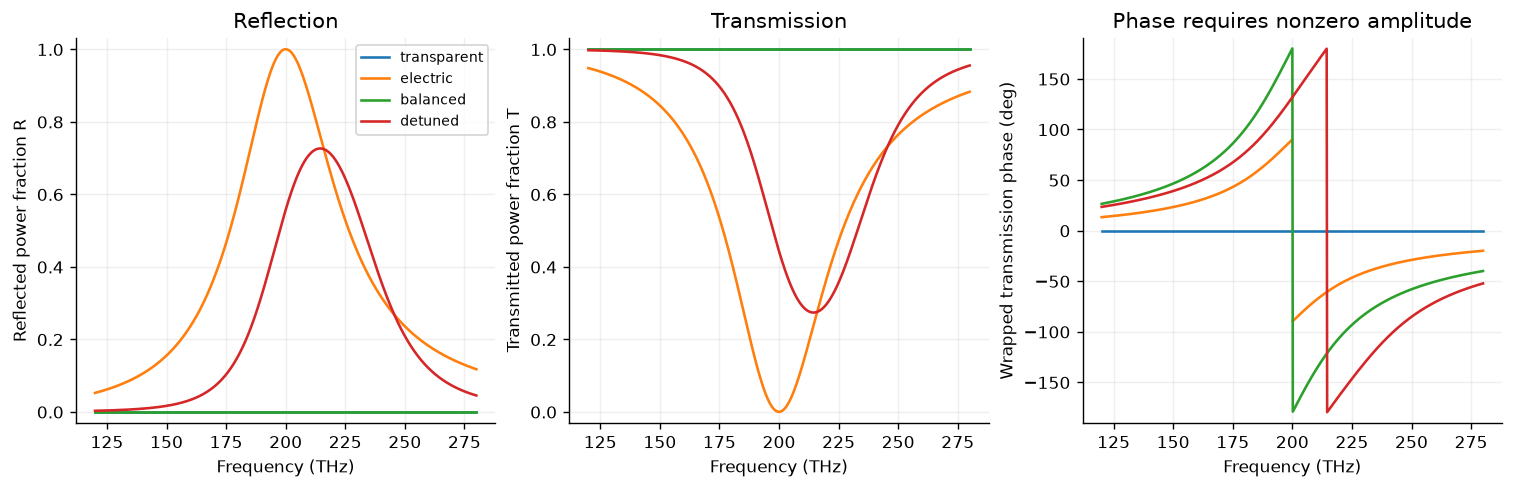

In [3]:
spectra={name:response(FREQUENCIES_THz,sheet,PHASE_FLOOR) for name,sheet in PRESETS.items()}
fig,axes=plt.subplots(1,3,figsize=(12,3.8),layout='constrained')
for name,v in spectra.items():
    axes[0].plot(FREQUENCIES_THz,v['R'],label=name)
    axes[1].plot(FREQUENCIES_THz,v['T'],label=name)
    axes[2].plot(FREQUENCIES_THz,v['phase_deg'],label=name)
axes[0].set(ylabel='Reflected power fraction R',ylim=(-.03,1.03),title='Reflection')
axes[1].set(ylabel='Transmitted power fraction T',ylim=(-.03,1.03),title='Transmission')
axes[2].set(ylabel='Wrapped transmission phase (deg)',ylim=(-190,190),title='Phase requires nonzero amplitude')
for ax in axes:ax.set_xlabel('Frequency (THz)');ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.show()

## 3. Add complex arrows

At a balanced response, reflection combines $C_e/2$ with $-C_m/2$, which
cancel. Transmission combines $C_e/2$ with $C_m/2$, which add. The arrows
are complex channel contributions in this model, not independently measured
radiated dipole fields. Both panels use the same complex-plane scale.

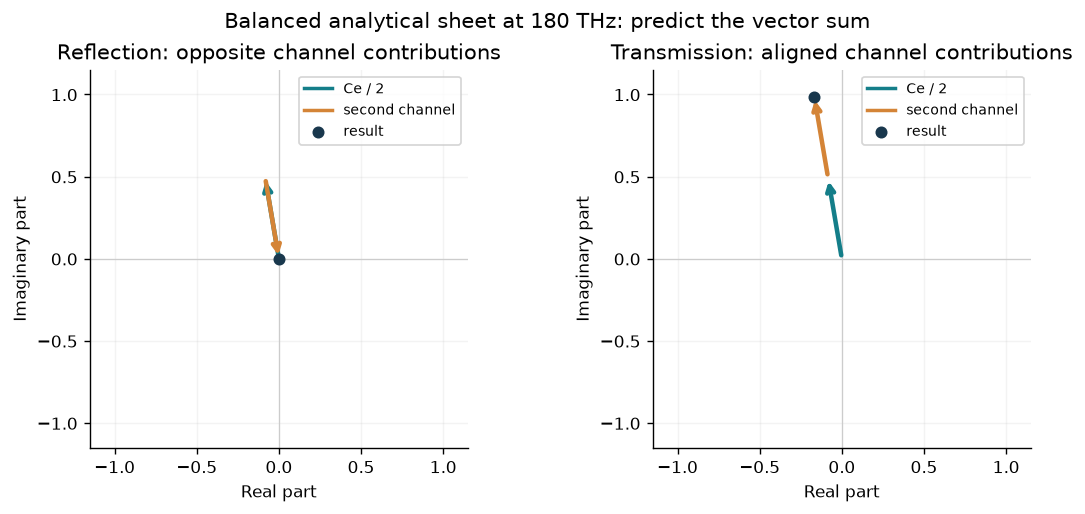

In [4]:
v=response(180.,PRESETS['balanced'])
fig,axes=plt.subplots(1,2,figsize=(9,4),layout='constrained')
for ax,second,title in [(axes[0],-v['cm']/2,'Reflection: opposite channel contributions'),(axes[1],v['cm']/2,'Transmission: aligned channel contributions')]:
    first=v['ce']/2
    for start,vector,color,label in [(0j,first,'#147e89','Ce / 2'),(first,second,'#d48437','second channel')]:
        ax.annotate('',xy=(start.real+vector.real,start.imag+vector.imag),xytext=(start.real,start.imag),arrowprops=dict(arrowstyle='->',color=color,lw=2.6))
        ax.plot([],[],color=color,lw=2,label=label)
    net=first+second;ax.scatter([net.real],[net.imag],color='#19384d',s=35,zorder=4,label='result')
    ax.axhline(0,color='.8',lw=.7);ax.axvline(0,color='.8',lw=.7)
    ax.set(xlim=(-1.15,1.15),ylim=(-1.15,1.15),xlabel='Real part',ylabel='Imaginary part',title=title,aspect='equal');ax.grid(alpha=.15);ax.legend(fontsize=8)
fig.suptitle('Balanced analytical sheet at 180 THz: predict the vector sum')
plt.show()

## 4. Phase and delay

For a balanced pair the group delay is the derivative of unwrapped phase:

$$
\tau_g=\frac{d\arg(t)}{d\omega}.
$$

The code has an independent closed-form derivative. A narrower channel
strength produces a sharper phase change and a larger peak delay, even while
the ideal matched model has unit transmission. This does not establish an
achromatic geometry or independent control of phase at every frequency.
The conversion is $\tau_g[\mathrm{fs}]=1000(2\pi)^{-1}d\phi/df[\mathrm{THz}]$.

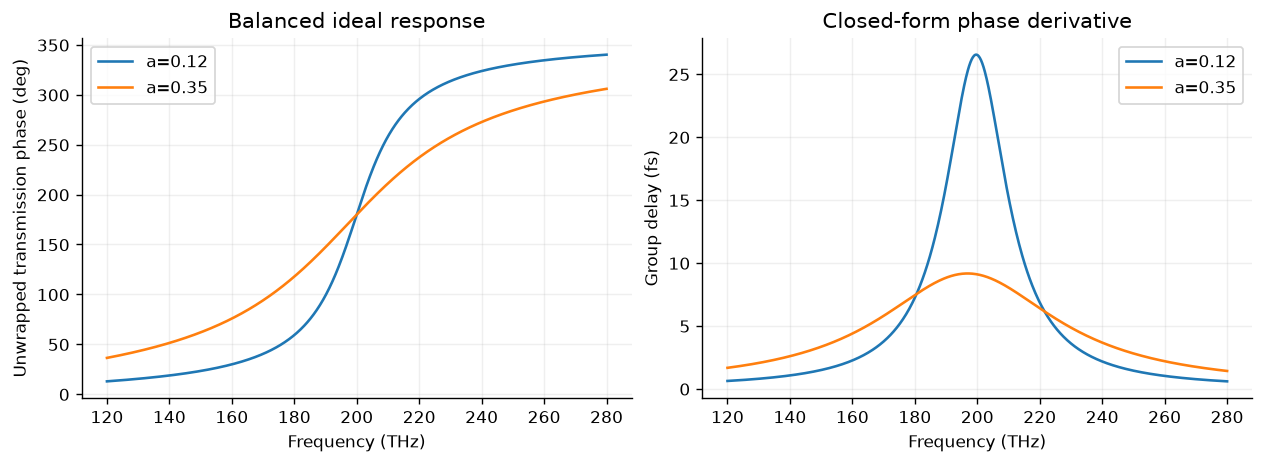

Channel strength,Group delay at resonance (fs),Max derivative check error (fs)
0.12,26.52582,0.002455519
0.35,9.094568,9.896492e-05


In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained');delay_rows=[]
for strength in [.12,.35]:
    sheet=Sheet(electric_strength=strength,magnetic_strength=strength)
    v=response(FREQUENCIES_THz,sheet)
    phase=np.unwrap(np.angle(v['t']))
    exact=channel_group_delay_fs(FREQUENCIES_THz,200.,strength)
    numeric=1000*np.gradient(phase,FREQUENCIES_THz)/(2*np.pi)
    max_error=float(np.max(abs(exact[2:-2]-numeric[2:-2])))
    assert max_error<.02
    delay_rows.append([strength,float(channel_group_delay_fs(200.,200.,strength)),max_error])
    axes[0].plot(FREQUENCIES_THz,np.rad2deg(phase),label=f'a={strength:g}')
    axes[1].plot(FREQUENCIES_THz,exact,label=f'a={strength:g}')
axes[0].set(ylabel='Unwrapped transmission phase (deg)',title='Balanced ideal response')
axes[1].set(ylabel='Group delay (fs)',title='Closed-form phase derivative')
for ax in axes:ax.set_xlabel('Frequency (THz)');ax.grid(alpha=.2);ax.legend()
plt.show()
table(['Channel strength','Group delay at resonance (fs)','Max derivative check error (fs)'],delay_rows)

## 5. Test and export

Power balance alone is weaker than a full two-port check. Verify $S^\dagger S=I$
for two-sided excitations as well as $R+T=1$ for one incident wave. Reciprocity
is explicit in the equal off-diagonal coefficients. These checks establish
consistency of this ideal analytical model, not the accuracy of a geometry.
The audit script also checks the electric-only shunt identity and limiting cases.

In [6]:
worst_balance=0.;worst_unitarity=0.
for name,sheet in PRESETS.items():
    v=response(FREQUENCIES_THz,sheet);S=scattering_matrix(FREQUENCIES_THz,sheet)
    balance=float(np.max(v['balance_error']))
    unitarity=float(np.max(abs(np.swapaxes(S.conj(),-1,-2)@S-np.eye(2))))
    assert balance<1e-12 and unitarity<1e-12
    worst_balance=max(worst_balance,balance);worst_unitarity=max(worst_unitarity,unitarity)
metadata=dict(topic_id='ms-02-scattering',model_version=MODEL_VERSION,model='analytical reciprocal mirror-symmetric lossless two-port sheet',frequency_unit='THz',phase_reference='ideal sheet plane',time_convention='exp(-i omega t)',exterior='equal real impedances, normal incidence, one polarization, specular ports only',source_sha256=hashlib.sha256((ROOT/'simulations/intro_sheet.py').read_bytes()).hexdigest(),environment=dict(python=platform.python_version(),numpy=np.__version__,matplotlib=matplotlib.__version__),phase_floor=PHASE_FLOOR,limitations=['No geometry or material dataset','No full-wave simulation','No diffraction or polarization conversion','No absorption or fabricated-device validation','Channel parameters are not retrieved dipole moments'])
data=dict(metadata=metadata,reference_frequency_THz=FREQUENCY_THz,presets=snapshots,frequencies_THz=FREQUENCIES_THz.tolist(),spectra={name:dict(R=v['R'].tolist(),T=v['T'].tolist(),phase_deg=[None if not np.isfinite(p) else float(p) for p in v['phase_deg']]) for name,v in spectra.items()},delay_checks=delay_rows,max_balance_error=worst_balance,max_unitarity_error=worst_unitarity)
(DATA/'sheet-response.json').write_text(json.dumps(data,indent=2,allow_nan=False)+'\n',encoding='utf-8')
with (DATA/'sheet-response.csv').open('w',newline='',encoding='utf-8') as handle:
    writer=csv.writer(handle);writer.writerow(['preset','frequency_THz','r_real','r_imag','t_real','t_imag','R','T','phase_deg'])
    for name,v in spectra.items():
        for j,f in enumerate(FREQUENCIES_THz):writer.writerow([name,float(f),float(v['r'][j].real),float(v['r'][j].imag),float(v['t'][j].real),float(v['t'][j].imag),float(v['R'][j]),float(v['T'][j]),'' if not np.isfinite(v['phase_deg'][j]) else float(v['phase_deg'][j])])
table(['Check','Worst error'],[['One-sided power balance',worst_balance],['Two-port unitarity',worst_unitarity]])
print('Saved sheet-response.json and sheet-response.csv; no nonfinite phases are serialized as numbers.')

Check,Worst error
One-sided power balance,6.661338e-16
Two-port unitarity,4.440892e-16


Saved sheet-response.json and sheet-response.csv; no nonfinite phases are serialized as numbers.


## Interpret the results

Explain why a zero-transmission phase is unusable, why a balanced ideal response
can have $T=1$ and a nonzero phase, and why this does not produce a unit-cell
geometry automatically. Change channel detuning and strength, then retain both
phase and amplitude. Test a new two-sided incident vector with the full $S$ matrix.

Chapter 2 will develop boundary conditions, field-to-power normalization, and
sheet descriptions in more detail. Chapter 3 supplies actual full-wave dielectric
ridge data. Chapter 4 counts outgoing diffraction channels. Chapter 5 tests
assembled geometries. Compare those evidence levels before making a device claim.

References: [Yu and Capasso, flat optics overview](https://capasso.seas.harvard.edu/publications/flat-optics-designer-metasurfaces),
[Decker et al., dielectric Huygens surfaces](https://doi.org/10.1002/adom.201400584).
The equations and computational figures here are an original ideal teaching model,
not a reproduction of those papers' geometries or reported efficiencies.